# S6 · Identification and empirical support

Partners were assigned at random within each classroom and round. This
notebook checks that children’s own characteristics do not predict the
rank of the partners they met, that rank differences are spread over the
whole session, and that every classroom and friendship group has enough
variation in rank gaps. Code: `code/si/S6_identification.R`.

In [ ]:
here::i_am("notebooks/si/S6_identification.qmd")
source(here::here("code", "00_helpers.R"))
source(here("code", "00_style.R"))
library(patchwork)
dir.create(here("output", "figures", "si"), recursive = TRUE, showWarnings = FALSE)

dyads    <- read_csv(here("data", "generated", "analysis_dyads.csv"),    show_col_types = FALSE)
students <- read_csv(here("data", "generated", "analysis_students.csv"), show_col_types = FALSE)

save_si_figure <- function(plot, name, width, height) {
  ggsave(here("output", "figures", "si", paste0(name, ".pdf")), plot, width = width, height = height)
  ggsave(here("output", "figures", "si", paste0(name, ".png")), plot, width = width, height = height, dpi = 300)
}

## Three measures of exposure

The raw gap mixes the partner’s rank with the child’s own rank, so it is
not a clean balance check. The demeaned partner rank compares the
partner with the rank the child could expect in that classroom and
round.

In [ ]:
# Three versions of the exposure of the focal child (the sender):
#   raw_gap               partner rank - own rank  (higher = met a higher-ranked partner)
#   partner_rank          the partner's rank only
#   partner_rank_demeaned partner rank - the rank she could expect: the mean
#                         rank of the other children active in that class-round
balance_data <- dyads %>%
  left_join(students %>% select(sender_id = student_id, female, attendance_z, gpa), by = "sender_id") %>%
  mutate(class_round  = factor(paste(class_id, round, sep = "_")),
         raw_gap      = receiver_rank - sender_rank,
         partner_rank = receiver_rank) %>%
  group_by(class_round) %>%
  mutate(expected_partner_rank = (sum(sender_rank) - sender_rank) / (n() - 1),
         partner_rank_demeaned = partner_rank - expected_partner_rank) %>%
  ungroup()

outcomes <- c(raw_gap = "A: Social Rank GAP (partner - sender)",
              partner_rank = "B: Partner Rank",
              partner_rank_demeaned = "C: Partner Rank (demeaned)")

## Table S16. Balance

In [ ]:
# Table S16: each outcome on each covariate alone (1-3) and on all three (4),
# with classroom-by-round FE and SE clustered by classroom
covariate_sets <- list("(1)" = "female", "(2)" = "attendance_z", "(3)" = "gpa",
                       "(4)" = "female + attendance_z + gpa")

balance_models <- expand_grid(outcome = names(outcomes), model = names(covariate_sets)) %>%
  mutate(fit = map2(outcome, model, ~ felm(
    as.formula(paste(.x, "~", covariate_sets[[.y]], "| class_round | 0 | class_id")),
    data = balance_data)))

table_s16 <- balance_models %>%
  mutate(coefs = map(fit, ~ summary(.x)$coefficients %>% as_tibble(rownames = "term")),
         r2 = map_dbl(fit, ~ summary(.x)$r.squared)) %>%
  select(-fit) %>%
  unnest(coefs) %>%
  transmute(panel = outcomes[outcome], model, term, estimate = Estimate,
            se = `Cluster s.e.`, p_value = `Pr(>|t|)`, r2)

table_s16 %>%
  mutate(cell = paste0(sprintf("%.4f", estimate), si_stars(p_value), " (", sprintf("%.4f", se), ")")) %>%
  select(panel, term, model, cell) %>%
  pivot_wider(names_from = model, values_from = cell, values_fill = "")

panel,term,(1),(2),(3),(4)
A: Social Rank GAP (partner - sender),female,0.0171 (0.0244),,,0.0462† (0.0242)
A: Social Rank GAP (partner - sender),attendance_z,,-0.0255** (0.0085),,0.0059 (0.0079)
A: Social Rank GAP (partner - sender),gpa,,,-0.1692*** (0.0279),-0.1784*** (0.0275)
B: Partner Rank,female,0.0005 (0.0014),,,0.0022 (0.0014)
B: Partner Rank,attendance_z,,-0.0019** (0.0006),,-0.0000 (0.0005)
B: Partner Rank,gpa,,,-0.0103*** (0.0019),-0.0105*** (0.0018)
C: Partner Rank (demeaned),female,-0.0001 (0.0003),,,-0.0002 (0.0003)
C: Partner Rank (demeaned),attendance_z,,-0.0000 (0.0002),,-0.0001 (0.0002)
C: Partner Rank (demeaned),gpa,,,0.0004 (0.0003),0.0005 (0.0004)


## Figure S15. Coefficients on a common scale

In [ ]:
# Coefficients of model (4) divided by the within-class-round SD of each
# outcome, so the three outcomes share a scale
outcome_sd <- balance_data %>%
  group_by(class_round) %>%
  mutate(across(all_of(names(outcomes)), ~ .x - mean(.x))) %>%
  ungroup() %>%
  summarise(across(all_of(names(outcomes)), sd)) %>%
  pivot_longer(everything(), names_to = "outcome", values_to = "sd")

figure_s15_data <- balance_models %>%
  filter(model == "(4)") %>%
  mutate(coefs = map(fit, ~ summary(.x)$coefficients %>% as_tibble(rownames = "term"))) %>%
  select(outcome, coefs) %>% unnest(coefs) %>%
  left_join(outcome_sd, by = "outcome") %>%
  mutate(estimate = Estimate / sd, se = `Cluster s.e.` / sd,
         outcome = factor(outcomes[outcome], levels = outcomes),
         term = recode(term, female = "Female", attendance_z = "Attendance", gpa = "GPA"))

short_outcomes <- setNames(c("Social Rank GAP\n(partner - sender)", "Partner Rank",
                             "Partner Rank\n(demeaned)"), outcomes)

The figure as in the SI, with its colors, labels and legends (code from
the script):

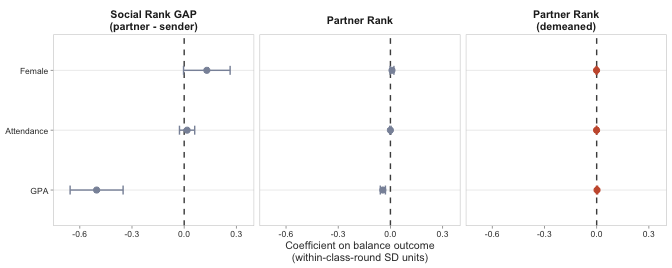

In [ ]:
figure_s15 <- figure_s15_data %>%
  mutate(outcome = factor(short_outcomes[as.character(outcome)], levels = short_outcomes),
         term = factor(term, levels = c("GPA", "Attendance", "Female")),
         highlight = outcome == "Partner Rank\n(demeaned)") %>%
  ggplot(aes(estimate, term, color = highlight)) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "grey30") +
  geom_errorbarh(aes(xmin = estimate - 1.96 * se, xmax = estimate + 1.96 * se), height = 0.15) +
  geom_point(size = 1.8) +
  facet_wrap(~ outcome, nrow = 1) +
  # The demeaned partner rank (the design-based check) in orange
  scale_color_manual(values = c(`FALSE` = color_slate, `TRUE` = color_highlight)) +
  scale_x_continuous(limits = c(-0.7, 0.35), breaks = c(-0.6, -0.3, 0, 0.3)) +
  labs(x = "Coefficient on balance outcome\n(within-class-round SD units)", y = NULL) +
  theme_si(8) +
  theme(strip.text = element_text(hjust = 0.5), panel.grid.major.y = element_line(color = "grey92"))
figure_s15

## Figure S16. Round by round

In [ ]:
# Round by round: each outcome on each covariate, classroom FE, SE by class
round_balance <- expand_grid(round_id = sort(unique(balance_data$round)),
                             outcome = names(outcomes),
                             covariate = c("female", "attendance_z", "gpa")) %>%
  mutate(result = pmap(list(round_id, outcome, covariate), function(r, y, x) {
    d <- balance_data %>% filter(round == r)
    if (n_distinct(d$class_id) < 3) return(NULL)
    fit <- felm(as.formula(paste(y, "~", x, "| class_id | 0 | class_id")), data = d)
    ct <- summary(fit)$coefficients
    tibble(estimate = ct[x, "Estimate"], se = ct[x, "Cluster s.e."])
  })) %>%
  unnest(result)

row_labels <- c(raw_gap = "Social Rank GAP\n(partner - sender)",
                partner_rank = "Partner Rank\n(assigned)",
                partner_rank_demeaned = "Partner Rank\n(demeaned)")

The figure as in the SI, with its colors, labels and legends (code from
the script):

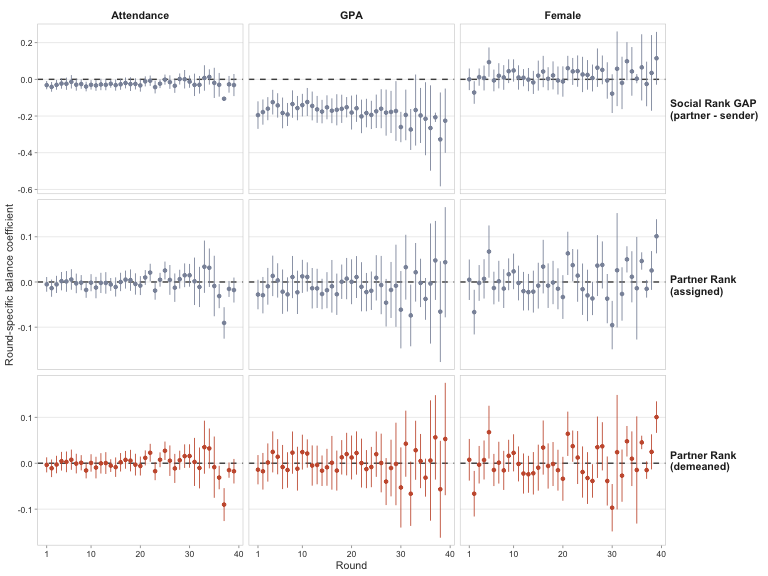

In [ ]:
figure_s16 <- round_balance %>%
  mutate(highlight = outcome == "partner_rank_demeaned",
         outcome = factor(row_labels[outcome], levels = row_labels),
         covariate = factor(recode(covariate, female = "Female", attendance_z = "Attendance", gpa = "GPA"),
                            levels = c("Attendance", "GPA", "Female"))) %>%
  ggplot(aes(round_id, estimate, color = highlight)) +
  geom_hline(yintercept = 0, linetype = "dashed", color = "grey30") +
  geom_linerange(aes(ymin = estimate - 1.96 * se, ymax = estimate + 1.96 * se), linewidth = 0.3) +
  geom_point(size = 0.9) +
  facet_grid(outcome ~ covariate, scales = "free_y") +
  # The demeaned partner rank in orange
  scale_color_manual(values = c(`FALSE` = color_slate, `TRUE` = color_highlight)) +
  scale_x_continuous(breaks = c(1, 10, 20, 30, 40)) +
  labs(x = "Round", y = "Round-specific balance coefficient") +
  theme_si(8) +
  theme(strip.text.x = element_text(hjust = 0.5), strip.text.y = element_text(angle = 0, hjust = 0))
figure_s16

## Figure S17. Demeaned exposure by covariate groups

In [ ]:
# Raw exposure after removing class-round means, by covariate group
# (attendance and GPA split at their median)
density_data <- balance_data %>%
  group_by(class_round) %>% mutate(gap_demeaned = raw_gap - mean(raw_gap)) %>% ungroup() %>%
  transmute(gap_demeaned,
            `A. Attendance` = if_else(attendance_z > median(attendance_z), "High", "Low"),
            `B. GPA`        = if_else(gpa > median(gpa), "High", "Low"),
            `C. Sex`        = if_else(female == 1, "High", "Low")) %>%
  pivot_longer(-gap_demeaned, names_to = "covariate", values_to = "group")

# low group in slate, high group in orange

The figure as in the SI, with its colors, labels and legends (code from
the script):

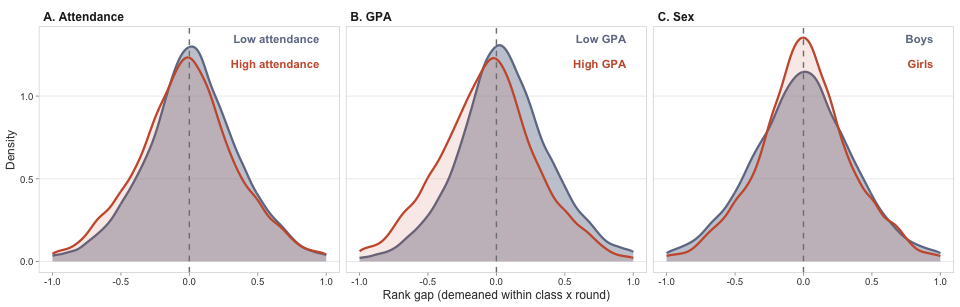

In [ ]:
group_names <- tribble(
  ~covariate,      ~Low,              ~High,
  "A. Attendance", "Low attendance",  "High attendance",
  "B. GPA",        "Low GPA",         "High GPA",
  "C. Sex",        "Boys",            "Girls"
)

figure_s17 <- ggplot(density_data, aes(gap_demeaned)) +
  geom_density(data = filter(density_data, group == "Low"),
               fill = color_slate, color = "#6F7A93", alpha = 0.5, linewidth = 0.8) +
  geom_density(data = filter(density_data, group == "High"),
               fill = color_highlight, color = color_highlight, alpha = 0.12, linewidth = 0.8) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "grey50") +
  facet_wrap(~ covariate, nrow = 1) +
  # The name of each group written inside its panel
  geom_text(data = group_names, aes(x = 0.95, y = 1.35, label = Low), hjust = 1,
            color = "#6F7A93", fontface = "bold", size = 3) +
  geom_text(data = group_names, aes(x = 0.95, y = 1.2, label = High), hjust = 1,
            color = color_highlight, fontface = "bold", size = 3) +
  coord_cartesian(xlim = c(-1, 1)) +
  labs(x = "Rank gap (demeaned within class x round)", y = "Density") +
  theme_si(9)
figure_s17

## Figure S18. Rank gaps by round

The figure as in the SI, with its colors, labels and legends (code from
the script):

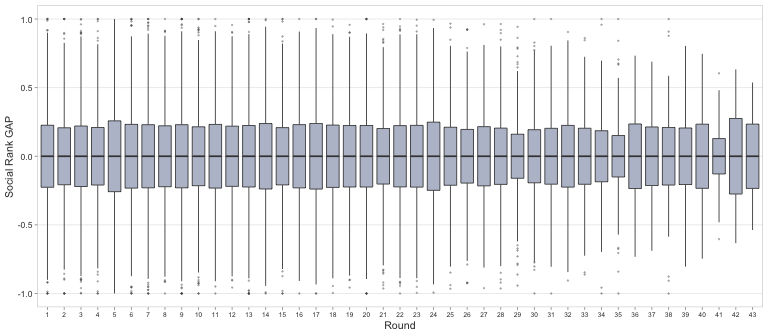

In [ ]:
# Figure S18: Social Rank GAP by round
figure_s18 <- ggplot(dyads, aes(factor(round), rank_gap)) +
  geom_boxplot(fill = color_slate_light, color = "grey25", linewidth = 0.3,
               outlier.size = 0.1, outlier.alpha = 0.3) +
  labs(x = "Round", y = "Social Rank GAP") +
  theme_si(8) + theme(axis.text.x = element_text(size = 5))
figure_s18

## Figure S19. One classroom round by round

Class 20 (21 children, 31 rounds), the classroom used for this figure in
the SI.

In [ ]:
# Figure S19: one classroom round by round. Class 20 (21 children, 31
# rounds) is the classroom shown in this SI figure. Kernel densities with
# half of Scott's bandwidth
# (sd * n^-1/5), close to the smoothing of the SI figure.
example_rounds <- 20

densities <- dyads %>% filter(class_id == example_rounds) %>%
  group_by(round) %>%
  reframe(as_tibble(density(rank_gap, bw = 0.5 * sd(rank_gap) * length(rank_gap)^(-1 / 5),
                            from = -1, to = 1, n = 256)[c("x", "y")])) %>%
  mutate(round_label = factor(paste("Round", round), levels = paste("Round", sort(unique(round)))))

The figure as in the SI, with its colors, labels and legends (code from
the script):

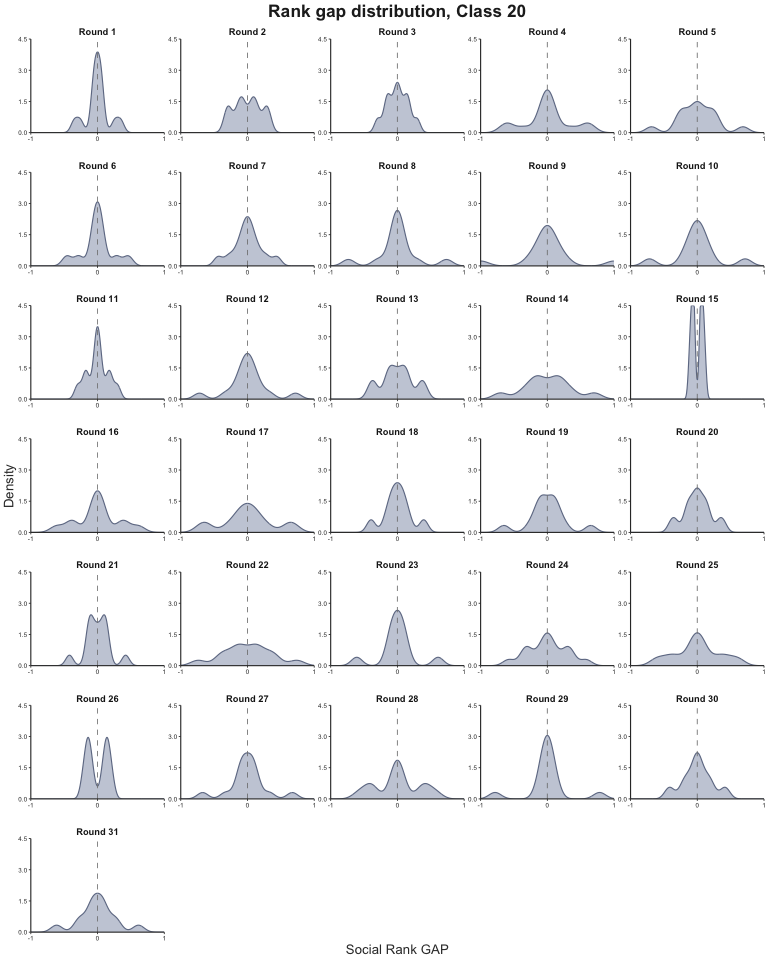

In [ ]:
figure_s19 <- ggplot(densities, aes(x, pmin(y, 4.5))) +
  geom_area(fill = color_slate_light, color = "#6F7A93", alpha = 0.8, linewidth = 0.4) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "grey50", linewidth = 0.3) +
  # "free" scales only to draw the axes in every panel; the limits are fixed below
  facet_wrap(~ round_label, ncol = 5, scales = "free") +
  # The same axes in every panel, a title and the SI theme
  scale_x_continuous(limits = c(-1, 1), breaks = c(-1, 0, 1), expand = c(0, 0)) +
  scale_y_continuous(limits = c(0, 4.5), breaks = c(0, 1.5, 3, 4.5), expand = c(0, 0),
                     labels = function(x) sprintf("%.1f", x)) +
  labs(title = sprintf("Rank gap distribution, Class %d", example_rounds),
       x = "Social Rank GAP", y = "Density") +
  theme_si_frame(6, l_axes = TRUE) +
  theme(strip.text = element_text(face = "bold", size = 7),
        plot.title = element_text(size = 13),
        axis.title = element_text(size = 10),
        panel.spacing.y = unit(4, "mm"))
figure_s19

## Figure S20. By classroom

The figure as in the SI, with its colors, labels and legends (code from
the script):

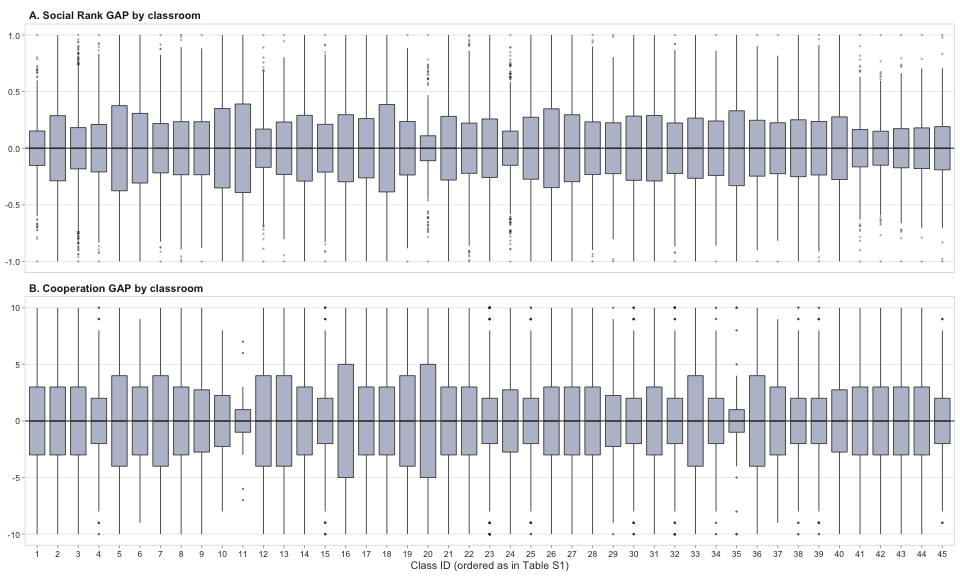

In [ ]:
# Figure S20: Social Rank GAP and Cooperation GAP by classroom
figure_s20 <- dyads %>%
  select(class_id, `A. Social Rank GAP by classroom` = rank_gap,
         `B. Cooperation GAP by classroom` = coop_gap) %>%
  pivot_longer(-class_id) %>%
  ggplot(aes(factor(class_id), value)) +
  geom_hline(yintercept = 0, color = "grey30", linewidth = 0.4) +
  geom_boxplot(fill = color_slate_light, color = "grey25", linewidth = 0.3,
               outlier.size = 0.1, outlier.alpha = 0.3) +
  facet_wrap(~ name, ncol = 1, scales = "free_y") +
  labs(x = "Class ID (ordered as in Table S1)", y = NULL) +
  theme_si(8)
figure_s20

## Figure S21. Support among mutual friends

In [ ]:
# Figure S21: how much rank-gap variation mutual friendships really have
support <- dyads %>%
  filter(friendship %in% c("Non-friends", "Mutual")) %>%
  group_by(friendship) %>%
  summarise(n = n(), sd = sd(rank_gap),
            share_025 = 100 * mean(abs(rank_gap) >= 0.25),
            share_050 = 100 * mean(abs(rank_gap) >= 0.50),
            classes_with_obs = n_distinct(class_id),
            classes_025 = n_distinct(class_id[abs(rank_gap) >= 0.25]),
            classes_050 = n_distinct(class_id[abs(rank_gap) >= 0.50]))
support

friendship,n,sd,share_025,share_050,classes_with_obs,classes_025,classes_050
Mutual,1288,0.2946900,35.55901,9.006211,45,45,32
Non-friends,13916,0.3605243,45.55907,17.505030,45,45,45


The figure as in the SI (code from the script): a “raincloud” for each
group (decisions as dots, a box plot and half a density), with the
support statistics under it.

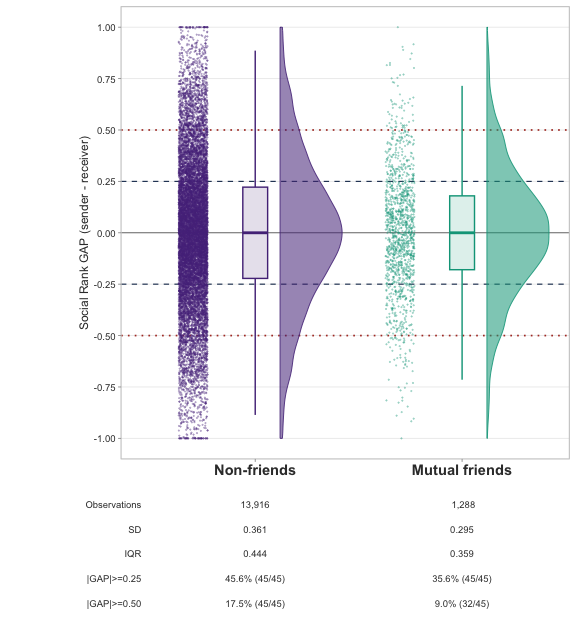

In [ ]:
# Figure S21 as in the SI: a "raincloud" (decisions as dots, a box plot and
# half a density) with the support statistics printed under each group
rain <- dyads %>%
  filter(friendship %in% c("Non-friends", "Mutual")) %>%
  mutate(group = if_else(friendship == "Mutual", "Mutual friends", "Non-friends"),
         x = if_else(group == "Non-friends", 1, 2))

half_density <- rain %>%
  group_by(group, x) %>%
  reframe(density(rank_gap, from = -1, to = 1, n = 256)[c("x", "y")] %>% as_tibble() %>%
            rename(gap = x, d = y)) %>%
  group_by(group) %>%
  mutate(width = 0.3 * d / max(d)) %>%
  ungroup()

rain_colors <- c("Non-friends" = color_non_friends, "Mutual friends" = color_mutual)

support_text <- support %>%
  mutate(group = if_else(friendship == "Mutual", "Mutual friends", "Non-friends"),
         x = if_else(group == "Non-friends", 1, 2)) %>%
  transmute(x,
            obs  = format(n, big.mark = ","),
            sd   = sprintf("%.3f", sd),
            iqr  = map_dbl(group, ~ IQR(rain$rank_gap[rain$group == .x])) %>% sprintf("%.3f", .),
            s025 = sprintf("%.1f%% (%d/45)", share_025, classes_025),
            s050 = sprintf("%.1f%% (%d/45)", share_050, classes_050)) %>%
  pivot_longer(-x, names_to = "row", values_to = "text") %>%
  mutate(y = -1.2 - 0.12 * match(row, c("obs", "sd", "iqr", "s025", "s050")))

row_names <- tibble(text = c("Observations", "SD", "IQR", "|GAP|>=0.25", "|GAP|>=0.50"),
                    y = -1.2 - 0.12 * (1:5))

figure_s21 <- ggplot() +
  geom_hline(yintercept = c(-0.25, 0.25), linetype = "dashed", color = "#1F3A5F", linewidth = 0.4) +
  geom_hline(yintercept = c(-0.5, 0.5), linetype = "dotted", color = "#B03A2E", linewidth = 0.6) +
  geom_hline(yintercept = 0, color = "grey40", linewidth = 0.3) +
  geom_point(data = rain, aes(x - 0.3, rank_gap, color = group), size = 0.05, alpha = 0.3,
             position = position_jitter(width = 0.07, height = 0, seed = 1)) +
  geom_boxplot(data = rain, aes(x, rank_gap, group = group, color = group, fill = group),
               width = 0.12, alpha = 0.15, outlier.shape = NA) +
  geom_polygon(data = half_density %>% group_by(group) %>%
                 reframe(gx = c(x[1] + 0.12, x[1] + 0.12 + width, x[1] + 0.12),
                         gy = c(-1, gap, 1)),
               aes(gx, gy, fill = group, color = group), alpha = 0.55, linewidth = 0.3) +
  geom_text(data = support_text, aes(x, y, label = text), size = 2.5, color = color_text) +
  geom_text(data = row_names, aes(0.45, y, label = text), size = 2.5, hjust = 1, color = color_text) +
  scale_color_manual(values = rain_colors) + scale_fill_manual(values = rain_colors) +
  scale_x_continuous(breaks = c(1, 2), labels = c("Non-friends", "Mutual friends")) +
  scale_y_continuous(breaks = seq(-1, 1, 0.25)) +
  coord_cartesian(ylim = c(-1, 1), clip = "off") +
  labs(x = NULL, y = "Social Rank GAP (sender - receiver)") +
  theme_si(9) +
  theme(axis.text.x = element_text(face = "bold", size = 11, color = color_text),
        plot.margin = margin(5, 5, 110, 60))
figure_s21

In [ ]:
save_table(table_s16, "S6_table_s16_balance")
save_table(round_balance, "S6_round_balance")
save_table(support, "S6_support_by_friendship")
save_si_figure(figure_s15, "S6_figure_s15_balance_sd", 7, 2.8)
save_si_figure(figure_s16, "S6_figure_s16_round_balance", 8, 6)
save_si_figure(figure_s17, "S6_figure_s17_densities", 10, 3.2)
save_si_figure(figure_s18, "S6_figure_s18_gap_by_round", 8, 3.5)
save_si_figure(figure_s19, "S6_figure_s19_class20_rounds", 8, 10)
save_si_figure(figure_s20, "S6_figure_s20_by_classroom", 10, 6)
save_si_figure(figure_s21, "S6_figure_s21_support", 6, 6.5)